# 가게 단위 QR 매칭 (상가 × 제로페이)

**목적**: 동 단위 QR가맹률을 넘어, 가게마다 QR이 있는지 확인해 "어느 가게에 QR을 깔지" 목록을 만든다.

**데이터**
- 소상공인 상가정보 (2026.06): 제주 음식·소매 가게 (상호, 주소, 세부 업종, 위경도)
- 제로페이 제주 가맹점 목록: QR 가맹점 (가맹점명, 주소, 최근 거래 여부)

**매칭 3단계**
1. **주소 맞추기**: 두 데이터 주소를 "시 + 도로명 + 건물번호"로 통일 → 같은 건물의 후보를 찾음
2. **이름 비교**: 같은 건물 안에서 상호명 유사도 ≥ 0.75면 같은 가게로 확정
3. **LLM 판정**: 애매한 쌍은 LLM이 하나씩 읽고 판정한 결과(`QR_LLM판정.csv`)를 불러옴
   - 프랜차이즈는 지점까지 일치해야 같은 가게 (예: 씨유 신창점 ≠ 씨유 산양점)

**결과**: 가게마다 **QR 있음 / 없음** + 관광 업종 여부
- 제로페이 목록의 `최근거래여부`는 "최근" 기준 기간을 알 수 없고, 1-3에서 실사용률을 뺀 것과 같은 이유(외국인 소비의 결과일 수 있음)로 사용하지 않는다.

In [ ]:
import pandas as pd, numpy as np, re
from difflib import SequenceMatcher
from rapidfuzz import fuzz, process      # pip install rapidfuzz
import matplotlib.pyplot as plt
from matplotlib import font_manager

have = {f.name for f in font_manager.fontManager.ttflist}
for name in ['AppleGothic', 'Malgun Gothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if name in have:
        plt.rcParams['font.family'] = name; break
plt.rcParams['axes.unicode_minus'] = False

DATA = 'data/'
STORE_FILE = DATA + '소상공인시장진흥공단_상가(상권)정보_제주_202606.csv'
ZP_FILE    = DATA + '제로페이_제주_가맹점.csv'
LLM_FILE   = 'QR_LLM판정.csv'
C3_FILE    = '마스터_C3_동업종_공급QR.csv'

AUTO_CUT = 0.75     # 2단계: 같은 주소 + 이름 유사도 이 값 이상이면 자동 확정

## 1. 데이터 불러오기
- 상가: 음식·소매 대분류만
- 제로페이: 분석 제외(시내버스, 제주 외 주소) 빼기

In [ ]:
s = pd.read_csv(STORE_FILE, encoding='utf-8-sig', low_memory=False)
s = s[s['상권업종대분류명'].isin(['음식', '소매'])].reset_index(drop=True)

z = pd.read_csv(ZP_FILE, encoding='utf-8-sig')
z = z[z['분석제외사유'].isna()].reset_index(drop=True)

print(f'상가 음식·소매: {len(s):,}곳 | 제로페이 가맹점: {len(z):,}곳')

## 2. 주소 키와 이름 정리
- 주소 키 = `시|도로명|건물번호` (예: `제주시|연삼로|786`)
- 이름 = 공백·특수문자·법인 표기(주식회사, (주) 등) 제거, 영문 소문자

In [ ]:
def akey_zp(addr):
    a = str(addr).replace('제주특별자치도', '')
    m = re.search(r'(제주시|서귀포시).*?([0-9가-힣]+(?:로|길)(?:\d+번?길)?)\s*(지하\s*)?(\d+(?:-\d+)?)', a)
    return f'{m.group(1)}|{m.group(2)}|{m.group(4)}' if m else None

def akey_store(r):
    road = str(r['도로명']).split()
    si = [t for t in road if t.endswith('시')]
    if not si or pd.isna(r['건물본번지']):
        return None
    no = str(int(r['건물본번지'])) + ('' if pd.isna(r['건물부번지']) else '-' + str(int(r['건물부번지'])))
    return f'{si[0]}|{road[-1]}|{no}'

STOP = r'주식회사|\(주\)|㈜|유한회사|농업회사법인|영농조합법인|제주점|본점|직영점'
def norm(x):
    x = re.sub(STOP, '', str(x) if pd.notna(x) else '')
    return re.sub(r'[^0-9a-zA-Z가-힣]', '', x).lower()

def sim(a, b):
    """한쪽 이름이 다른 쪽에 통째로 들어 있으면 1, 아니면 문자열 유사도"""
    if not a or not b: return 0
    if len(min(a, b, key=len)) >= 2 and (a in b or b in a): return 1.0
    return SequenceMatcher(None, a, b).ratio()

z['ak'] = z['도로명주소'].map(akey_zp)
z['nm'] = z['가맹점명'].map(norm)
s['ak'] = s.apply(akey_store, axis=1)
s['nm'] = s['상호명'].map(norm)
s['nm2'] = (s['상호명'].fillna('') + s['지점명'].fillna('')).map(norm)   # 지점명 붙인 버전

print(f"주소 키 생성률  상가 {s['ak'].notna().mean():.1%} | 제로페이 {z['ak'].notna().mean():.1%}")

## 3. 1·2단계: 같은 주소 안에서 이름 비교 → 자동 확정

In [ ]:
zg = z.groupby('ak').groups
best_sc, best_j, same_addr = [], [], []
for _, r in s.iterrows():
    sc, jj = 0, None
    if r['ak'] in zg:
        for j in zg[r['ak']]:
            v = max(sim(r['nm'], z.at[j, 'nm']), sim(r['nm2'], z.at[j, 'nm']))
            if v > sc: sc, jj = v, j
    best_sc.append(sc); best_j.append(jj); same_addr.append(r['ak'] in zg if r['ak'] else False)

s['주소일치'], s['유사도'], s['z_idx'] = same_addr, best_sc, best_j
s['자동매칭'] = s['유사도'] >= AUTO_CUT

print(f"같은 주소에 제로페이 가맹점이 있는 가게: {s['주소일치'].mean():.1%}")
print(f"이름까지 일치 (자동 확정, 유사도 ≥ {AUTO_CUT}): {s['자동매칭'].mean():.1%}")

## 4. 3단계 후보: 애매한 쌍 만들기
- **같은주소_애매**: 같은 건물인데 이름 유사도 0.4~0.75
- **동내_이름**: 자동 매칭 안 된 가게 × 자동 매칭 안 된 제로페이(음식·소매류), 같은 동에서 이름 유사도 ≥ 0.6 또는 한쪽이 다른 쪽에 포함 (주소 표기가 달라도 찾기 위함)

In [ ]:
s['ks'] = s['표준산업분류명'].str.replace(';', ',')
z['음식소매'] = z['업종명'].isin(set(s['ks'])) | z['업종명'].str.contains('음식|소매|커피|제과|주점|편의점|슈퍼', na=False)

used = set(s.loc[s['자동매칭'], 'z_idx'].astype(int))
zu = z[z['음식소매'] & ~z.index.isin(used)]
zud = zu.groupby('행정동명').groups
su = s[~s['자동매칭']]

cand = []
for i, r in su.iterrows():
    if r['행정동명'] not in zud: continue
    g = zu.loc[zud[r['행정동명']]]
    names = dict(zip(g.index, g['nm']))
    for nmx in {r['nm'], r['nm2']}:
        if len(nmx) < 2: continue
        for _, sc, j in process.extract(nmx, names, scorer=fuzz.ratio, score_cutoff=60, limit=3):
            cand.append((i, j, sc / 100, '동내_이름'))
        for j, zn in names.items():
            if len(zn) >= 2 and (zn in nmx or nmx in zn):
                cand.append((i, j, 1.0, '동내_이름'))
for i, r in su[(su['유사도'] >= 0.4) & (su['유사도'] < AUTO_CUT)].iterrows():
    cand.append((i, int(r['z_idx']), r['유사도'], '같은주소_애매'))

CAND = (pd.DataFrame(cand, columns=['s', 'z', '유사도', '후보유형'])
          .sort_values('유사도', ascending=False).drop_duplicates(['s', 'z']))
CAND['상가업소번호'] = CAND['s'].map(s['상가업소번호'])
CAND['제로페이_가맹점명'] = CAND['z'].map(z['가맹점명'])
CAND['제로페이_도로명주소'] = CAND['z'].map(z['도로명주소'])
print(f'LLM 판정 대상 후보쌍: {len(CAND):,}개')
display(CAND['후보유형'].value_counts().to_frame('쌍 수'))

## 5. LLM 판정 불러오기
- 후보쌍마다 "같은 가게인가" Y/N (판정 기준: 주소가 같거나 같은 곳으로 볼 수 있고, 이름이 같은 사업체인가 / 프랜차이즈는 지점 일치 / 애매하면 N)
- 가게 번호 + 가맹점명 + 주소로 붙이므로 다시 돌려도 결과가 같음

In [ ]:
KEY = ['상가업소번호', '제로페이_가맹점명', '제로페이_도로명주소']
LLM = pd.read_csv(LLM_FILE, encoding='utf-8-sig')
CAND = CAND.merge(LLM[KEY + ['판정']], on=KEY, how='left')

print(f"판정 누락: {CAND['판정'].isna().sum()}쌍  (0이어야 함)")
display(CAND['판정'].value_counts().to_frame('쌍 수'))

print('\n[예시] Y로 판정된 쌍')
show = CAND.assign(상가명=CAND['s'].map(s['상호명']), 상가주소=CAND['s'].map(s['도로명주소']))
display(show[show['판정'] == 'Y'].sample(10, random_state=0)[['상가명', '상가주소', '제로페이_가맹점명', '제로페이_도로명주소', '후보유형']])
print('[예시] N으로 판정된 쌍 (이름 유사도 높은데 다른 가게)')
display(show[(show['판정'] == 'N') & (show['유사도'] >= 0.9)].sample(10, random_state=0)[['상가명', '상가주소', '제로페이_가맹점명', '제로페이_도로명주소']])

## 6. QR 있음 / 없음 + 관광 업종
- **QR 있음**: 매칭된 제로페이 가맹점이 있음
- **QR 없음**: 매칭된 제로페이 가맹점 없음

**관광 업종** (외국인 관광객이 살 만한 물건·음식을 파는 가게)
- 음식: 전부 포함, 단 유흥주점·무도 유흥주점·구내식당 제외
- 소매: 편의점, 슈퍼마켓, 그 외 기타 종합 소매(소품샵), 화장품, 약국, 기념품점, 예술품, 의류(기타·여성·남성·유아·액세서리·신발·가방), 건강보조식품, 수산물, 건어물/젓갈, 주류, 생수/음료
- 제외 예: 채소/과일(산지 유통·온라인 판매 다수), 반찬, 정육점, 가구, 가전, 철물, 연료 등

In [ ]:
y = CAND[CAND['판정'] == 'Y'].sort_values('유사도', ascending=False).drop_duplicates('s').set_index('s')['z']
z_of = s['z_idx'].where(s['자동매칭']).fillna(y)          # 자동 확정 우선, 없으면 LLM 판정

s['매칭방법'] = np.select([s['자동매칭'], z_of.notna()], ['주소+이름', 'LLM판정'], default='')
s['제로페이명'] = z_of.map(lambda j: z.at[int(j), '가맹점명'] if pd.notna(j) else None)
s['QR상태'] = np.where(z_of.isna(), 'QR 없음', 'QR 있음')

FOOD_OUT = ['일반 유흥 주점', '무도 유흥 주점', '구내식당']
RETAIL_IN = ['편의점', '슈퍼마켓', '그 외 기타 종합 소매업', '화장품 소매업', '약국', '기념품점', '예술품 소매업',
             '기타 의류 소매업', '여성 의류 소매업', '남성 의류 소매업', '유아용 의류 소매업',
             '액세서리/잡화 소매업', '신발 소매업', '가방 소매업',
             '건강보조식품 소매업', '수산물 소매업', '건어물/젓갈 소매업', '주류 소매업', '생수/음료 소매업']
sub = s['상권업종소분류명']
s['관광업종'] = np.where(s['상권업종대분류명'] == '음식', ~sub.isin(FOOD_OUT), sub.isin(RETAIL_IN))

print('[단계별 매칭률]')
print(f"  1·2단계 자동 확정 (같은 주소 + 이름 유사): {s['매칭방법'].eq('주소+이름').mean():.1%}")
print(f"  + LLM 판정: {z_of.notna().mean():.1%}")
print(f"\n관광 업종 가게: {s['관광업종'].sum():,}곳 / 전체 {len(s):,}곳")
display(pd.crosstab(s['관광업종'].map({True: '관광 업종', False: '그 외'}), s['QR상태'], normalize='index')
          .mul(100).round(1).assign(가게수=s['관광업종'].map({True: '관광 업종', False: '그 외'}).value_counts()))

## 7. 검증: 동별 QR가맹률이 기존 집계(C3)와 같은 방향인가

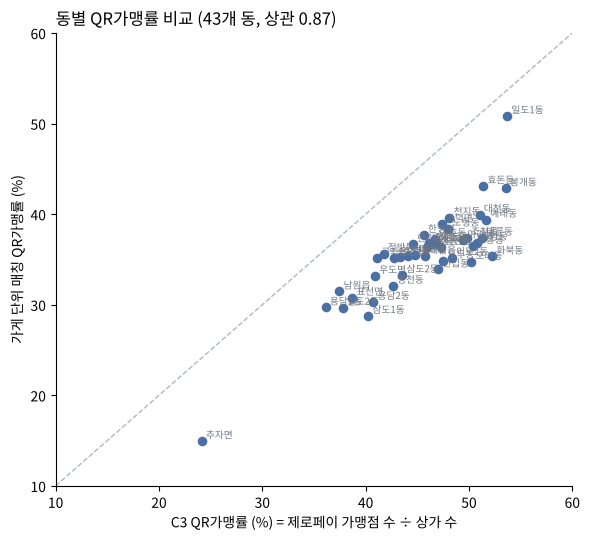

In [ ]:
c3 = pd.read_csv(C3_FILE, encoding='utf-8-sig')
c3 = c3[c3['업종명'].isin(['음식점업', '소매업'])].groupby('행정동명')[['QR가맹점', '사업체수']].sum()
cmp = pd.concat([s.groupby('행정동명')['QR상태'].apply(lambda v: (v != 'QR 없음').mean()).rename('가게매칭'),
                 (c3['QR가맹점'] / c3['사업체수']).rename('C3')], axis=1).dropna()
r = cmp.corr().iloc[0, 1]
print(f'동별 QR가맹률 상관: {r:.2f} | 평균 가게매칭 {cmp["가게매칭"].mean():.1%} vs C3 {cmp["C3"].mean():.1%}')

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(cmp['C3'] * 100, cmp['가게매칭'] * 100, color='#4a6fa5', s=35)
for d, row in cmp.iterrows():
    ax.annotate(d, (row['C3'] * 100, row['가게매칭'] * 100), fontsize=7, color='#6e7781', xytext=(3, 2), textcoords='offset points')
lim = [10, 60]; ax.plot(lim, lim, color='#afb8c1', lw=1, ls='--')
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('C3 QR가맹률 (%) = 제로페이 가맹점 수 ÷ 상가 수'); ax.set_ylabel('가게 단위 매칭 QR가맹률 (%)')
ax.set_title(f'동별 QR가맹률 비교 (43개 동, 상관 {r:.2f})', loc='left')
for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig('QR매칭_검증.png', dpi=200, bbox_inches='tight'); plt.show()

## 8. 저장

In [ ]:
OUT = s[['행정동코드', '행정동명', '상가업소번호', '상호명', '지점명', '도로명주소',
         '상권업종대분류명', '상권업종중분류명', '상권업종소분류명', '위도', '경도',
         '관광업종', 'QR상태', '매칭방법', '제로페이명']].rename(
    columns={'상권업종대분류명': '대분류', '상권업종중분류명': '중분류', '상권업종소분류명': '세부업종'})
OUT.to_csv('QR_가게단위_매칭.csv', index=False, encoding='utf-8-sig')
print('저장: QR_가게단위_매칭.csv', OUT.shape)
display(OUT['QR상태'].value_counts(normalize=True).mul(100).round(1).to_frame('비율(%)'))

## 9. 해석과 한계
- 가게 단위 매칭 QR가맹률은 C3 집계보다 약 10%p 낮지만, 동별 순위는 거의 같다 (상관 0.87).
  - C3는 "제로페이 가맹점 수 ÷ 상가 수"라 폐업했거나 상가 DB에 없는 가맹점까지 분자에 들어가 높게 나온다.
  - 반대로 이름이 크게 다르게 등록된 QR 가게는 여기서 "QR 없음"으로 남을 수 있다 → 가게 목록은 실행 전 현장 확인용 참고 자료.